<a href="https://colab.research.google.com/github/aayushttimalsina/pytorch/blob/main/exercise_of_regression_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
#exercise of the regression model

#Q1
#Create a straight line dataset using the linear regression formula (weight * X + bias).
#Set weight=0.3 and bias=0.9 there should be at least 100 datapoints total.
#Split the data into 80% training, 20% testing.
#Plot the training and testing data so it becomes visual.


In [3]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import numpy as np

In [5]:
## lets create the data first

weight = 0.3
bias = 0.9

#create the steps and start and end point

start = 0
end = 1
step = 0.01

X = torch.arange(start, end, step).unsqueeze(1)
y = weight*X + bias

print(X.shape, y.shape)
len(X), len(y), X.dtype, y.dtype
X[:10], y[:10]

torch.Size([100, 1]) torch.Size([100, 1])


(tensor([[0.0000],
         [0.0100],
         [0.0200],
         [0.0300],
         [0.0400],
         [0.0500],
         [0.0600],
         [0.0700],
         [0.0800],
         [0.0900]]),
 tensor([[0.9000],
         [0.9030],
         [0.9060],
         [0.9090],
         [0.9120],
         [0.9150],
         [0.9180],
         [0.9210],
         [0.9240],
         [0.9270]]))

In [6]:
### we will split the data

train_split = int(0.8 * len(X) )

X_train, y_train = X[: train_split  ], y[: train_split]
X_test, y_test = X[train_split:], y[train_split:]

len(X_train), len(y_train), len(X_test), len(y_test )

(80, 80, 20, 20)

In [7]:
##plot the data

def plot_predictions(train_data = X_train, train_labels = y_train,
                    test_data = X_test, test_labels = y_test, predictions = None):
   """
   plot training data and test data and compare the predictions
   """
   plt.figure(figsize=(10,7))

   plt.scatter(train_data, train_labels, c="b", s=4, label="training data")
   plt.scatter(test_data, test_labels, c="g", s=4, label="testing data")

   if predictions is not None:
       plt.scatter(test_data, predictions, c="r", s=4, label="predictions")

   plt.legend(prop={"size":14})


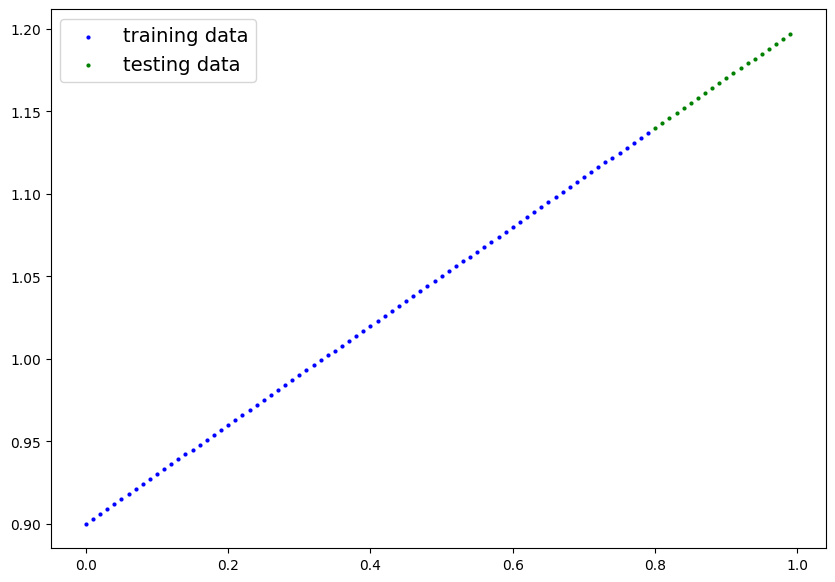

In [17]:
plot_predictions()

In [9]:
class LinearRegressionModel(nn.Module):
  def __init__(self):
    super().__init__()
    self.weights = nn.Parameter(torch.randn(1, requires_grad=True, dtype= torch.float))
    self.bias = nn.Parameter(torch.randn(1, requires_grad=True, dtype=torch.float))

  def forward(self, x: torch.Tensor) -> torch.Tensor:
    return self.weights * x + self.bias


In [22]:
## we can also use nn.liner instead of nn.parameter

class LinearRegressionModel1(nn.Module):
  def __init__(self):
    super().__init__()
    self.linear_layer = nn.Linear(in_features=1, out_features=1)

  def forward(self, x:torch.Tensor) -> torch.Tensor:
    return self.linear_layer(x)




In [23]:
#model_0 for the nn.linear

torch.manual_seed(42)
model_0 = LinearRegressionModel1()
model_0.state_dict()

OrderedDict([('linear_layer.weight', tensor([[0.7645]])),
             ('linear_layer.bias', tensor([0.8300]))])

In [24]:
## x_test for the nn.linear
with torch.inference_mode():
  y_preds1 = model_0(X_test)
y_preds1

tensor([[1.4416],
        [1.4493],
        [1.4569],
        [1.4646],
        [1.4722],
        [1.4799],
        [1.4875],
        [1.4952],
        [1.5028],
        [1.5104],
        [1.5181],
        [1.5257],
        [1.5334],
        [1.5410],
        [1.5487],
        [1.5563],
        [1.5640],
        [1.5716],
        [1.5793],
        [1.5869]])

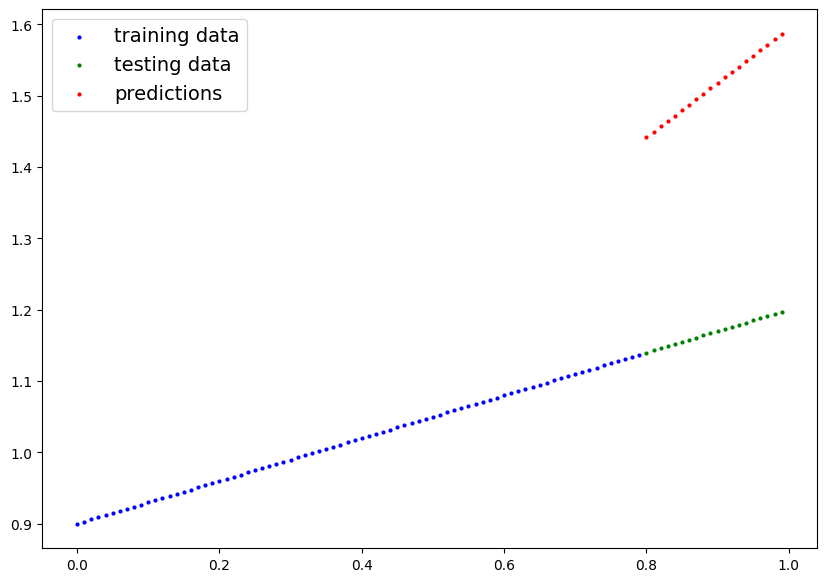

In [25]:
##predictions_plot for nn.linear

plot_predictions(predictions=y_preds1)

In [10]:
##model_1 for the nn.parameter

torch.manual_seed(42)
model_1 = LinearRegressionModel()
model_1.state_dict()

OrderedDict([('weights', tensor([0.3367])), ('bias', tensor([0.1288]))])

In [14]:
# x_test for nn.parameter

with torch.inference_mode():
 y_pred = model_1(X_test)
y_pred

tensor([[0.3982],
        [0.4015],
        [0.4049],
        [0.4083],
        [0.4116],
        [0.4150],
        [0.4184],
        [0.4217],
        [0.4251],
        [0.4285],
        [0.4318],
        [0.4352],
        [0.4386],
        [0.4419],
        [0.4453],
        [0.4487],
        [0.4520],
        [0.4554],
        [0.4588],
        [0.4621]])

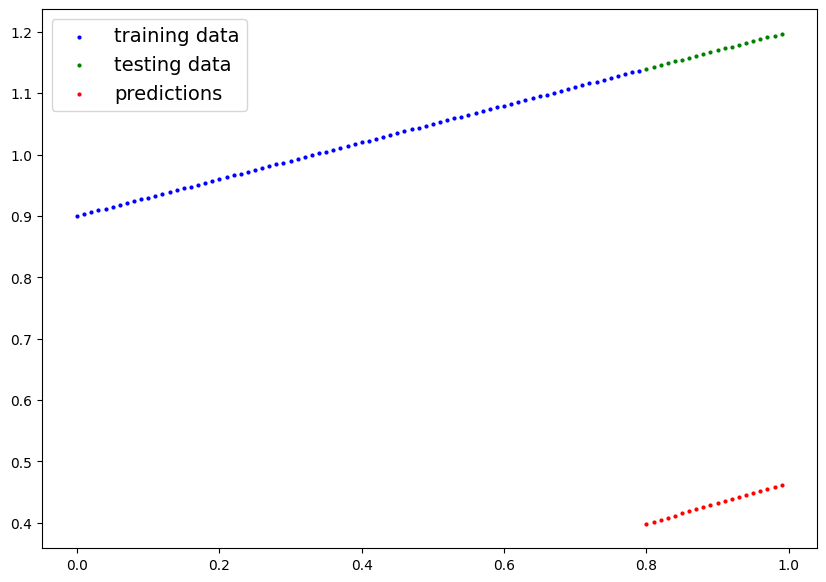

In [16]:
#predictions for nn.Parameter
plot_predictions(predictions=y_pred)

In [ ]:
#Q3

#Create a loss function and optimizer using nn.L1Loss() and torch.optim.SGD(params, lr) respectively.
#Set the learning rate of the optimizer to be 0.01 and the parameters to optimize should be the model parameters from the model you created in 2.C
#Write a training loop to perform the appropriate training steps for 300 epochs.
#The training loop should test the model on the test dataset every 20 epochs.

In [27]:
# creating loss and the optimizer
loss_fn = nn.L1Loss()
optim1 = torch.optim.SGD(params= model_0.parameters(), lr = 0.01 )
optim2 = torch.optim.SGD(params= model_1.parameters(), lr = 0.01 )

In [ ]:
## building a training loop